# 05 · Purchase-time features

**Question:** Which features known at purchase time separate late from on-time
orders, and how complete is each one?

Source: the `order_features` materialized view (`sql/03_order_features.sql`),
loaded with `src/features.py`. One row per delivered order, Jan 2017 - Aug 2018.
Every feature passes the leakage test in CLAUDE.md rule 1.

This notebook only *looks* at the features; nothing here is used by the model.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.stats.proportion import proportion_confint

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from features import CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET, load_features

sns.set_theme(style="whitegrid")

df = load_features()
print(f"{len(df):,} orders, {df[TARGET].mean():.1%} late")


def late_rate(data, by):
    """Late rate (%) per group with a 95% Wilson confidence interval."""
    out = data.groupby(by, observed=True)[TARGET].agg(orders="count", late="sum")
    low, high = proportion_confint(out["late"], out["orders"], method="wilson")
    out["late_pct"] = 100 * out["late"] / out["orders"]
    out["ci_low"], out["ci_high"] = 100 * low, 100 * high
    return out.round(2)


def plot_late_rate(table, title):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.errorbar(table.index.astype(str), table["late_pct"],
                yerr=[table["late_pct"] - table["ci_low"], table["ci_high"] - table["late_pct"]],
                marker="o", capsize=4)
    ax.axhline(100 * df[TARGET].mean(), color="grey", linestyle="--", linewidth=1, label="overall")
    ax.set(title=title, xlabel="", ylabel="Late (%)")
    ax.legend()
    plt.xticks(rotation=30)
    plt.show()

96,203 orders, 6.8% late


## 1. Missing values

**Question:** Which features have missing values, how many, and why?

In [2]:
missing = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES].isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["pct"] = (100 * missing["missing"] / len(df)).round(2)
missing.sort_values("missing", ascending=False)

,missing,pct
seller_prior_late_rate,4966,5.16
main_category,1356,1.41
distance_km,477,0.50
total_weight_g,16,0.02
total_volume_cm3,16,0.02


**Observations:**

- 

## 2. Promised delivery days

**Question:** Are orders with a short promise more likely to be late?

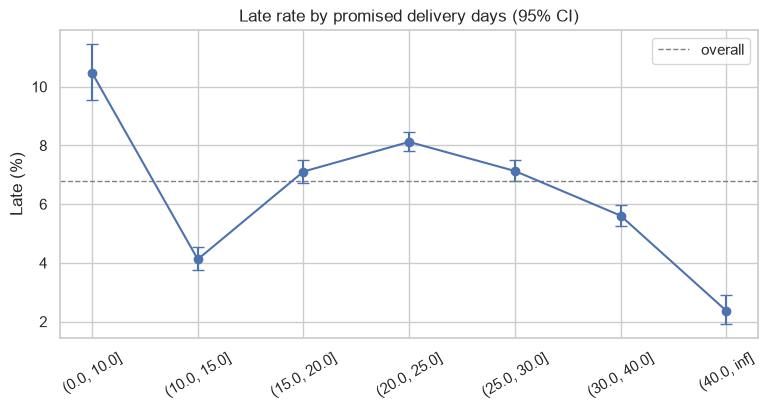

,orders,late,late_pct,ci_low,ci_high
promised_group,,,,,
"(0.0, 10.0]",3945,413,10.47,9.55,11.46
"(10.0, 15.0]",10094,416,4.12,3.75,4.53
"(15.0, 20.0]",16624,1182,7.11,6.73,7.51
"(20.0, 25.0]",26373,2142,8.12,7.80,8.46
"(25.0, 30.0]",19559,1395,7.13,6.78,7.50
"(30.0, 40.0]",16015,898,5.61,5.26,5.97
"(40.0, inf]",3593,85,2.37,1.92,2.92


In [3]:
bins = [0, 10, 15, 20, 25, 30, 40, np.inf]
df["promised_group"] = pd.cut(df["promised_days"], bins=bins)
table = late_rate(df, "promised_group")
plot_late_rate(table, "Late rate by promised delivery days (95% CI)")
table

**Observations:**

- 

## 3. Seller-customer distance

**Question:** Does the late rate rise with distance? Orders with no distance
(zip missing from geolocation) are shown as their own group.

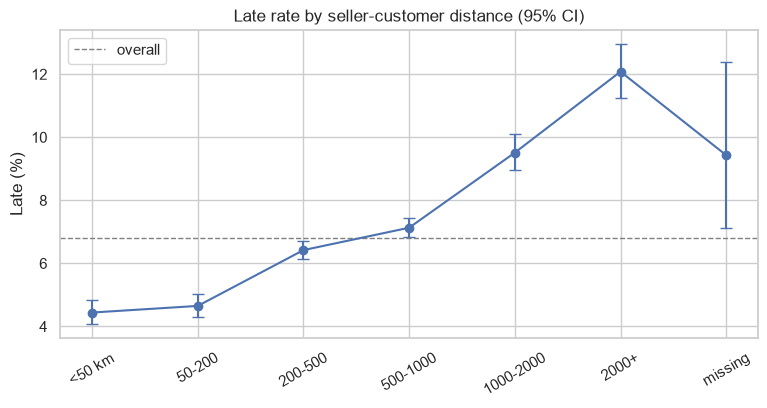

,orders,late,late_pct,ci_low,ci_high
distance_group,,,,,
<50 km,11719,520,4.44,4.08,4.83
50-200,12849,597,4.65,4.30,5.02
200-500,30173,1938,6.42,6.15,6.71
500-1000,25687,1832,7.13,6.82,7.45
1000-2000,9712,924,9.51,8.95,10.11
2000+,5586,675,12.08,11.25,12.96
missing,477,45,9.43,7.13,12.39


In [4]:
bins = [-np.inf, 50, 200, 500, 1000, 2000, np.inf]
labels = ["<50 km", "50-200", "200-500", "500-1000", "1000-2000", "2000+"]
df["distance_group"] = (pd.cut(df["distance_km"], bins=bins, labels=labels)
                        .cat.add_categories("missing").fillna("missing"))
table = late_rate(df, "distance_group")
plot_late_rate(table, "Late rate by seller-customer distance (95% CI)")
table

**Observations:**

- 

## 4. Seller history

**Question:** Are sellers who were often late *before* this order more likely
to be late again? Sellers with no delivered orders yet are their own group.

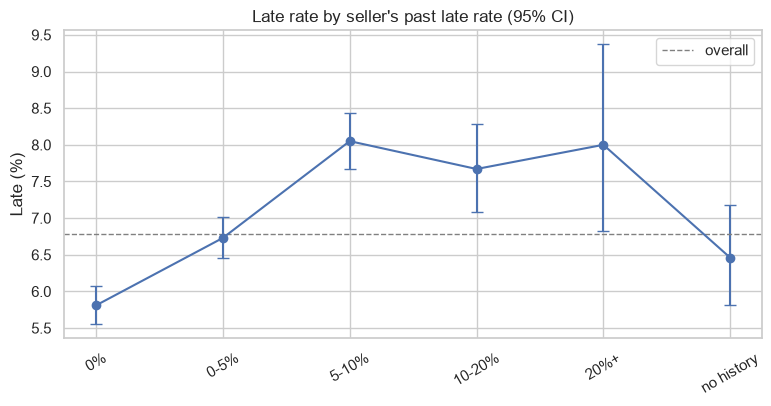

,orders,late,late_pct,ci_low,ci_high
seller_history_group,,,,,
0%,30144,1750,5.81,5.55,6.08
0-5%,32319,2175,6.73,6.46,7.01
5-10%,19263,1550,8.05,7.67,8.44
10-20%,7762,595,7.67,7.09,8.28
20%+,1749,140,8.00,6.82,9.37
no history,4966,321,6.46,5.81,7.18


In [5]:
bins = [-np.inf, 0, 0.05, 0.10, 0.20, np.inf]
labels = ["0%", "0-5%", "5-10%", "10-20%", "20%+"]
df["seller_history_group"] = (pd.cut(df["seller_prior_late_rate"], bins=bins, labels=labels)
                              .cat.add_categories("no history").fillna("no history"))
table = late_rate(df, "seller_history_group")
plot_late_rate(table, "Late rate by seller's past late rate (95% CI)")
table

A rate from 2 past orders is far less reliable than one from 200. How many
past orders do sellers usually have at purchase time?

In [6]:
df["seller_prior_orders"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1)

count    96203.0
mean       171.0
std        285.6
min          0.0
10%          2.0
25%         12.0
50%         52.0
75%        182.0
90%        511.0
max       1798.0
Name: seller_prior_orders, dtype: float64

**Observations:**

- 

## 5. Payment type and product category

**Question:** Does the late rate differ by how the customer pays, or by what
they buy? Only the 15 largest categories are shown.

In [7]:
late_rate(df, "main_payment_type")

,orders,late,late_pct,ci_low,ci_high
main_payment_type,,,,,
boleto,19140,1404,7.34,6.97,7.71
credit_card,72612,4868,6.70,6.52,6.89
debit_card,1481,79,5.33,4.30,6.60
voucher,2970,180,6.06,5.26,6.98


In [8]:
top = df["main_category"].value_counts().head(15).index
late_rate(df[df["main_category"].isin(top)], "main_category").sort_values("late_pct", ascending=False)

,orders,late,late_pct,ci_low,ci_high
main_category,,,,,
baby,2752,224,8.14,7.18,9.22
electronics,2501,192,7.68,6.70,8.79
health_beauty,8576,647,7.54,7.00,8.12
bed_bath_table,9180,687,7.48,6.96,8.04
watches_gifts,5472,406,7.42,6.75,8.14
auto,3784,278,7.35,6.56,8.22
furniture_decor,6140,448,7.30,6.67,7.97
telephony,4066,291,7.16,6.40,7.99
perfumery,3043,202,6.64,5.81,7.58


**Observations:**

- 

## 6. Overlap between numeric features

**Question:** Which numeric features carry nearly the same information
(|correlation| above ~0.8)? Spearman is used because many features are skewed.

In [9]:
corr = df[NUMERIC_FEATURES].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
         .stack().rename("spearman")
         .rename_axis(["feature_a", "feature_b"]).reset_index())
pairs[pairs["spearman"].abs() > 0.8].sort_values("spearman", key=abs, ascending=False)

,feature_a,feature_b,spearman
253,seller_prior_orders,seller_prior_late,0.875965


**Observations:**

- 

## Decisions from this notebook

- 